# Entrega 2 · Gradient Boosting — Grupo 19
**ELCO 2022 | Clasificación del estado de pago de créditos**

**Objetivo:** desarrollar y evaluar modelos de clasificación basados en boosting secuencial de árboles para identificar créditos con retrasos. Se estudian dos conjuntos de variables: A (características del crédito) y B (características del crédito e indicadores del hogar).

**Reglas metodológicas:** el objetivo objetivo_atraso equivale a P2110 == 2; no se utilizan P2110, P2108 ni identificadores como predictores. El preprocesamiento se ajusta solo con entrenamiento; las configuraciones y los umbrales se seleccionan exclusivamente con validación y la prueba se reserva para la evaluación final. Los resultados describen retrasos observados en la encuesta, no predicción prospectiva validada.


## 0. Librerias / configuración




In [ ]:
from pathlib import Path
import os, json, hashlib, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, precision_score, recall_score, f1_score,
                             roc_auc_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from IPython.display import display

SEED = 42
TARGET, GROUP = 'objetivo_atraso', 'DIRECTORIO'
OUT = Path('resultados_entrega2_v3'); OUT.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0], '| sklearn:', sklearn.__version__)

Python: 3.13.18 | sklearn: 1.6.1


## 1. Lectura y controles de integridad

In [ ]:
ROOT = Path.cwd()
name = 'ELCO_2022_creditos_ahorro_laboral_consolidado.csv'
candidates = [ROOT/'data'/name, ROOT/name, ROOT/'files'/name,
              ROOT/'entrega_elco'/name, Path('/mnt/data')/name,
              Path('/mnt/data')/'ELCO_2022_creditos_ahorro_laboral_consolidado (1).csv']
RUTA = next((p for p in candidates if p.is_file()), None)
if RUTA is None:
    raise FileNotFoundError(f'No se encontró {name}. Colócalo en data/ o junto al notebook.')
df = pd.read_csv(RUTA, encoding='utf-8-sig')
assert len(df) == 4013 and df[GROUP].nunique() == 3020, 'La base no coincide con la versión de referencia.'
assert df[TARGET].notna().all() and df[TARGET].isin([0,1]).all()
assert (df[TARGET].astype(int) == (df['P2110'] == 2).astype(int)).all()
assert df[GROUP].notna().all()
base = df.copy()
base.loc[pd.to_numeric(base['P2107S1'], errors='coerce') == 9999, 'P2107S1'] = np.nan
print('Fuente:', RUTA, '| créditos:', len(base), '| hogares:', base[GROUP].nunique(),
      '| retrasos:', int(base[TARGET].sum()), f'({base[TARGET].mean():.1%})')
print('SHA256 del CSV:', hashlib.sha256(RUTA.read_bytes()).hexdigest())


Fuente: /content/ELCO_2022_creditos_ahorro_laboral_consolidado.csv | créditos: 4013 | hogares: 3020 | retrasos: 675 (16.8%)
SHA256 del CSV: f1da82c6a0d6df962c8740d751ade21383ea890c2b97a078a052a8d6a3113eb4


## 2. Definición de conjuntos de variables A y B
Se emplean variables del crédito para el conjunto A y se agregan indicadores de ahorro y empleo del hogar en el conjunto B. Se excluyen el saldo actual y cualquier variable que reproduzca directamente el objetivo.


In [ ]:
CATEGORICAS = ['P2097','P2098','P2106']
NUMERICAS_A = ['P2099S2','P2104','P2105S1','P2107S1']
HOGAR = ['n_personas_ahorro','n_personas_con_ingresos','n_personas_que_ahorran',
         'prop_que_ahorran_sobre_con_ingresos','n_personas_con_cuenta',
         'n_personas_laboral','n_personas_trabajo_semana']
FEATURES = {'A': CATEGORICAS + NUMERICAS_A,
            'B': CATEGORICAS + NUMERICAS_A + HOGAR}
for grupo, cols in FEATURES.items():
    faltan = set(cols) - set(base.columns)
    assert not faltan, f'Faltan columnas para {grupo}: {faltan}'
    assert not {'P2110','P2108',GROUP,TARGET,'P2107S2','P2109S1'} & set(cols)
for c in NUMERICAS_A + HOGAR:
    base[c] = pd.to_numeric(base[c], errors='coerce')
# Los códigos de categoría se tratan como etiquetas, no como cantidades ordenadas.
for c in CATEGORICAS:
    base[c] = base[c].astype('string').fillna('__FALTANTE__').astype(str)
print('A:', FEATURES['A']); print('Variables adicionales B:', HOGAR)
print('Faltantes en predictores B:'); display(base[FEATURES['B']].isna().sum().to_frame('faltantes').T)


A: ['P2097', 'P2098', 'P2106', 'P2099S2', 'P2104', 'P2105S1', 'P2107S1']
Variables adicionales B: ['n_personas_ahorro', 'n_personas_con_ingresos', 'n_personas_que_ahorran', 'prop_que_ahorran_sobre_con_ingresos', 'n_personas_con_cuenta', 'n_personas_laboral', 'n_personas_trabajo_semana']
Faltantes en predictores B:


,P2097,P2098,P2106,P2099S2,P2104,P2105S1,P2107S1,n_personas_ahorro,n_personas_con_ingresos,n_personas_que_ahorran,prop_que_ahorran_sobre_con_ingresos,n_personas_con_cuenta,n_personas_laboral,n_personas_trabajo_semana
faltantes,0,0,0,0,0,135,128,0,0,0,163,0,0,0


## 3. Partición 70/15/15 por hogar
Se utiliza GroupShuffleSplit con semillas fijas para separar entrenamiento, validación y prueba sin compartir hogares entre particiones. Las proporciones son aproximadas porque los hogares pueden tener distinto número de créditos.


In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED)
i_train, i_tmp = next(gss.split(base, base[TARGET], groups=base[GROUP]))
train, tmp = base.iloc[i_train].copy(), base.iloc[i_tmp].copy()
gss2 = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED+1)
i_val, i_test = next(gss2.split(tmp, tmp[TARGET], groups=tmp[GROUP]))
val, test = tmp.iloc[i_val].copy(), tmp.iloc[i_test].copy()
for a,b in [(train,val),(train,test),(val,test)]:
    assert set(a[GROUP]).isdisjoint(set(b[GROUP]))
for parte in (train,val,test):
    assert set(parte[TARGET].unique()) == {0,1}
resumen_split = pd.DataFrame([{'partición': k, 'créditos':len(p), 'hogares':p[GROUP].nunique(),
                              'retrasos':int(p[TARGET].sum()), 'tasa_retrasos':p[TARGET].mean()}
                             for k,p in [('train',train),('validación',val),('prueba',test)]])
display(resumen_split)
resumen_split.to_csv(OUT/'particiones.csv', index=False)


,partición,créditos,hogares,retrasos,tasa_retrasos
0,train,2808,2114,486,0.173077
1,validación,613,453,94,0.153344
2,prueba,592,453,95,0.160473


## 4. Modelo: boosting de árboles e hiperparámetros
HistGradientBoostingClassifier construye árboles secuencialmente. Se imputan valores numéricos con la mediana aprendida en entrenamiento y se codifican las categorías con One-Hot. La clase minoritaria recibe peso inversamente proporcional a su frecuencia calculado solo en entrenamiento. La búsqueda es pequeña y explícita para permitir reproducibilidad.

In [ ]:
CONFIGS = [
    {'learning_rate':0.05, 'max_iter':120, 'max_leaf_nodes':15, 'min_samples_leaf':20, 'l2_regularization':1.0},
    {'learning_rate':0.05, 'max_iter':200, 'max_leaf_nodes':15, 'min_samples_leaf':30, 'l2_regularization':1.0},
    {'learning_rate':0.10, 'max_iter':120, 'max_leaf_nodes':15, 'min_samples_leaf':30, 'l2_regularization':1.0},
    {'learning_rate':0.05, 'max_iter':150, 'max_leaf_nodes':7,  'min_samples_leaf':20, 'l2_regularization':2.0},
]
UMBRALES = np.round(np.arange(.10, .91, .05), 2)

def pipeline(cols, config):
    cats = [c for c in CATEGORICAS if c in cols]
    nums = [c for c in cols if c not in cats]
    pre = ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median', add_indicator=True), nums),
        ('categoricas', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cats)
    ], remainder='drop')
    return Pipeline([('preparacion', pre), ('modelo', HistGradientBoostingClassifier(
        loss='log_loss', early_stopping=False, random_state=SEED, **config))])

def weights(y):
    counts = pd.Series(y).value_counts()
    return np.array([len(y)/(2*counts.loc[int(v)]) for v in y], dtype=float)

def metricas(y, p, thr):
    y = np.asarray(y, dtype=int); p = np.asarray(p, dtype=float)
    pred = (p >= thr).astype(int)
    return {'precision':precision_score(y,pred,zero_division=0),
            'recall':recall_score(y,pred,zero_division=0),
            'f1':f1_score(y,pred,zero_division=0),
            'pr_auc':average_precision_score(y,p),
            'roc_auc':roc_auc_score(y,p),
            'balanced_accuracy':balanced_accuracy_score(y,pred)}

def elegir_umbral(y, p):
    scores = [f1_score(y, (p>=u).astype(int), zero_division=0) for u in UMBRALES]
    return float(UMBRALES[int(np.argmax(scores))])


## 5. Entrenamiento y selección en validación
Para cada conjunto A/B se comparan cuatro configuraciones mediante PR-AUC en validación. Se selecciona la mejor (desempate por orden de configuración) y luego se determina el umbral que maximiza F1 en validación.

In [ ]:
candidatos = []; seleccionados = {}
for conjunto, cols in FEATURES.items():
    for idx, cfg in enumerate(CONFIGS, start=1):
        pipe = pipeline(cols, cfg)
        pipe.fit(train[cols], train[TARGET], modelo__sample_weight=weights(train[TARGET]))
        pv = pipe.predict_proba(val[cols])[:,1]
        row = {'conjunto':conjunto, 'config':idx, 'pr_auc_validacion':average_precision_score(val[TARGET],pv),
               'configuracion':json.dumps(cfg)}
        candidatos.append(row)
        if conjunto not in seleccionados or row['pr_auc_validacion'] > seleccionados[conjunto]['pr_auc_validacion']:
            seleccionados[conjunto] = {**row, 'pipeline':pipe, 'proba_val':pv, 'columnas':cols}
comparacion_validacion = pd.DataFrame(candidatos)
display(comparacion_validacion[['conjunto','config','pr_auc_validacion']].round(4))
comparacion_validacion.to_csv(OUT/'busqueda_validacion.csv',index=False)
for grupo, item in seleccionados.items():
    item['umbral'] = elegir_umbral(val[TARGET], item['proba_val'])
    print(f"{grupo}: configuración {item['config']}, PR-AUC val {item['pr_auc_validacion']:.4f}, umbral F1 val {item['umbral']:.2f}")


,conjunto,config,pr_auc_validacion
0,A,1,0.4052
1,A,2,0.3998
2,A,3,0.4099
3,A,4,0.4156
4,B,1,0.3993
5,B,2,0.4038
6,B,3,0.4088
7,B,4,0.4123


A: configuración 4, PR-AUC val 0.4156, umbral F1 val 0.70
B: configuración 4, PR-AUC val 0.4123, umbral F1 val 0.55


## 6. Evaluación final sobre prueba
La evaluación de prueba se realiza una sola vez con las configuraciones y umbrales congelados. La comparación A/B sigue el criterio acordado: Δ recall ≥ 0,05 y Δ precisión ≥ −0,03.

In [ ]:
resultados = []; predicciones = {}
for grupo, item in seleccionados.items():
    cols = item['columnas']; pipe = item['pipeline']; thr = item['umbral']
    pt = pipe.predict_proba(test[cols])[:,1]
    predicciones[grupo] = pt
    mv = metricas(val[TARGET], item['proba_val'], thr)
    mt = metricas(test[TARGET], pt, thr)
    resultados.append({'modelo':grupo, 'algoritmo':'HistGradientBoosting',
                       'configuracion':item['config'], 'umbral_validacion':thr,
                       **{'val_'+k:v for k,v in mv.items()},
                       **{'test_'+k:v for k,v in mt.items()}})
res = pd.DataFrame(resultados).set_index('modelo')
display(res.round(4))
res.to_csv(OUT/'metricas_v3.csv')
drec = float(res.loc['B','test_recall']-res.loc['A','test_recall'])
dprec = float(res.loc['B','test_precision']-res.loc['A','test_precision'])
print(f'Δ recall B−A = {drec:+.4f}; Δ precisión B−A = {dprec:+.4f}')
print('Criterio académico alcanzado:', 'Sí' if drec >= .05 and dprec >= -.03 else 'No')
print('Referencia sin modelo: PR-AUC aproximadamente igual a prevalencia en prueba =', round(test[TARGET].mean(),4))


,algoritmo,configuracion,umbral_validacion,val_precision,val_recall,val_f1,val_pr_auc,val_roc_auc,val_balanced_accuracy,test_precision,test_recall,test_f1,test_pr_auc,test_roc_auc,test_balanced_accuracy
modelo,,,,,,,,,,,,,,,
A,HistGradientBoosting,4,0.70,0.5200,0.4149,0.4615,0.4156,0.7462,0.6728,0.5263,0.4211,0.4678,0.4612,0.7413,0.6743
B,HistGradientBoosting,4,0.55,0.4194,0.5532,0.4771,0.4123,0.7594,0.7072,0.3456,0.4947,0.4069,0.4565,0.7472,0.6578


Δ recall B−A = +0.0737; Δ precisión B−A = -0.1807
Criterio académico alcanzado: No
Referencia sin modelo: PR-AUC aproximadamente igual a prevalencia en prueba = 0.1605


## 7. Evidencias visuales: matrices de confusión y curvas PR

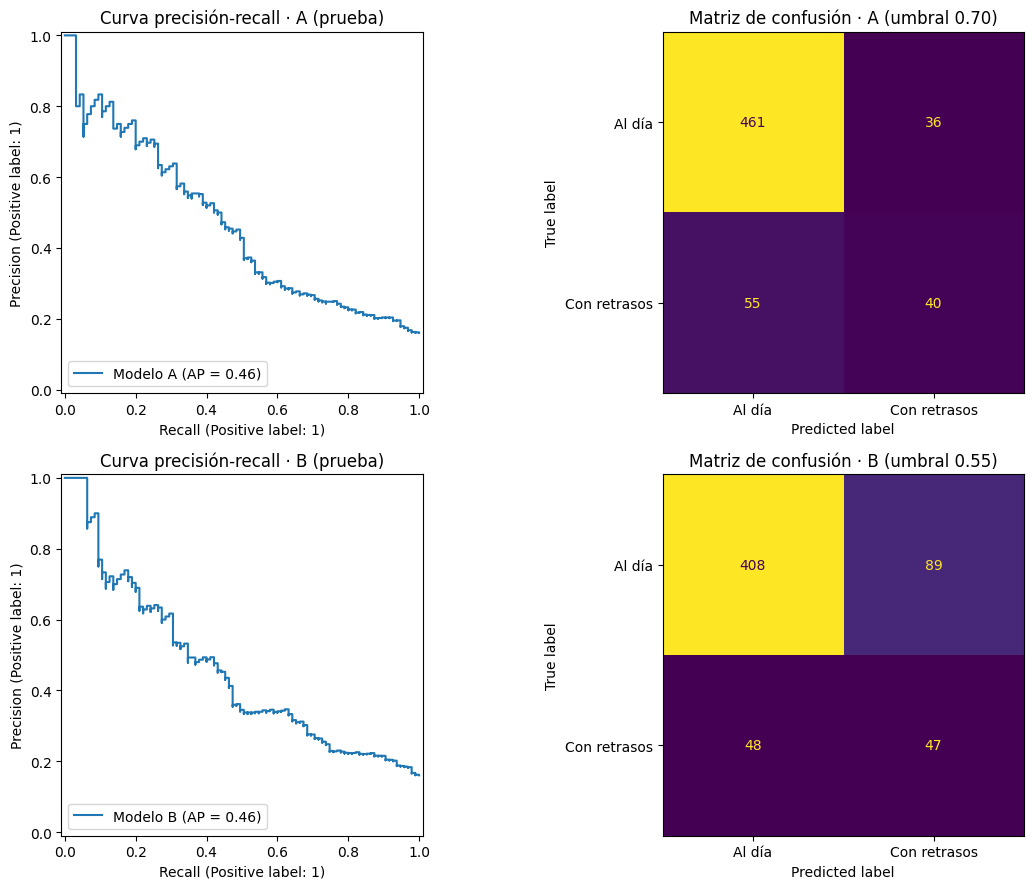

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12,9))
for i, grupo in enumerate(('A','B')):
    thr = seleccionados[grupo]['umbral']; p = predicciones[grupo]
    PrecisionRecallDisplay.from_predictions(test[TARGET], p, ax=axes[i,0], name=f'Modelo {grupo}')
    axes[i,0].set_title(f'Curva precisión-recall · {grupo} (prueba)')
    ConfusionMatrixDisplay.from_predictions(test[TARGET], (p>=thr).astype(int), ax=axes[i,1],
        display_labels=['Al día','Con retrasos'], colorbar=False)
    axes[i,1].set_title(f'Matriz de confusión · {grupo} (umbral {thr:.2f})')
fig.tight_layout(); fig.savefig(OUT/'evaluacion_v3.png',dpi=160); plt.show()


## 8. Sensibilidad sin año de inicio
La variable P2099S2 puede reflejar antigüedad y sesgo de supervivencia. Se hace una sensibilidad adicional sin esta variable. Para evitar ajustar con prueba, se repite la selección de configuración y umbral solo con validación, y luego se informa el resultado final. No se utiliza esta sensibilidad para cambiar retrospectivamente el modelo principal.

In [ ]:
sensibilidad = []
for grupo in ('A','B'):
    cols = [c for c in FEATURES[grupo] if c != 'P2099S2']
    cfg = CONFIGS[seleccionados[grupo]['config']-1]  # hiperparámetros principales, sin reoptimizar
    pipe = pipeline(cols,cfg)
    pipe.fit(train[cols],train[TARGET],modelo__sample_weight=weights(train[TARGET]))
    pv = pipe.predict_proba(val[cols])[:,1]
    thr = elegir_umbral(val[TARGET],pv)
    pt = pipe.predict_proba(test[cols])[:,1]
    sensibilidad.append({'modelo':grupo, 'sin_anio_pr_auc_val':average_precision_score(val[TARGET],pv),
                         'sin_anio_umbral_val':thr,
                         **{'sin_anio_test_'+k:v for k,v in metricas(test[TARGET],pt,thr).items()}})
display(pd.DataFrame(sensibilidad).round(4))
pd.DataFrame(sensibilidad).to_csv(OUT/'sensibilidad_sin_anio.csv',index=False)


,modelo,sin_anio_pr_auc_val,sin_anio_umbral_val,sin_anio_test_precision,sin_anio_test_recall,sin_anio_test_f1,sin_anio_test_pr_auc,sin_anio_test_roc_auc,sin_anio_test_balanced_accuracy
0,A,0.2308,0.55,0.2624,0.6105,0.3671,0.2641,0.6682,0.6413
1,B,0.2394,0.45,0.2446,0.7158,0.3646,0.2884,0.6912,0.6466


## 9. Interpretabilidad: importancia por permutación
La importancia por permutación se calcula en validación, no en prueba. Mide pérdida de PR-AUC al permutar cada predictor; no representa causalidad.

In [ ]:
importancias = {}
for grupo, item in seleccionados.items():
    cols = item['columnas']
    pi = permutation_importance(item['pipeline'], val[cols], val[TARGET],
                                scoring='average_precision', n_repeats=5,
                                random_state=SEED, n_jobs=1)
    tab = pd.DataFrame({'variable':cols, 'caida_pr_auc_media':pi.importances_mean,
                        'desviacion':pi.importances_std}).sort_values('caida_pr_auc_media',ascending=False)
    importancias[grupo] = tab
    tab.to_csv(OUT/f'importancia_permutacion_{grupo}.csv',index=False)
    print('Importancia por permutación:',grupo); display(tab.round(4))


Importancia por permutación: A


,variable,caida_pr_auc_media,desviacion
3,P2099S2,0.2177,0.0137
4,P2104,0.0253,0.0260
2,P2106,0.0105,0.0129
6,P2107S1,0.0091,0.0290
5,P2105S1,-0.0088,0.0097
1,P2098,-0.0177,0.0169
0,P2097,-0.0207,0.0037


Importancia por permutación: B


,variable,caida_pr_auc_media,desviacion
3,P2099S2,0.2028,0.0161
2,P2106,0.0155,0.0131
13,n_personas_trabajo_semana,0.0109,0.0043
10,prop_que_ahorran_sobre_con_ingresos,0.0061,0.0174
6,P2107S1,0.0047,0.0257
4,P2104,0.0043,0.0201
12,n_personas_laboral,0.0034,0.0012
7,n_personas_ahorro,0.0023,0.0048
9,n_personas_que_ahorran,0.0011,0.0106
8,n_personas_con_ingresos,-0.0005,0.0015


## 10. Artefactos reproducibles
Se guardan los pipelines A/B completos, metadatos de entrada, umbrales y métricas en archivos locales.


In [ ]:
metadata = {'algoritmo':'HistGradientBoostingClassifier', 'semilla':SEED,
            'fuente_csv':RUTA.name, 'sha256_csv':hashlib.sha256(RUTA.read_bytes()).hexdigest(),
            'n_creditos':len(base), 'n_hogares':int(base[GROUP].nunique()),
            'criterio_seleccion':'max PR-AUC validacion; umbral max F1 validacion',
            'separacion':'GroupShuffleSplit por DIRECTORIO, 70/15/15 aproximado',
            'sklearn_version':sklearn.__version__,
            'limitacion':'Clasificacion de estado observado, no prediccion prospectiva validada'}
for grupo, item in seleccionados.items():
    ruta = OUT/f'pipeline_gradient_boosting_{grupo}.joblib'
    joblib.dump(item['pipeline'],ruta)
    metadata[grupo] = {'variables':item['columnas'], 'umbral':item['umbral'],
                       'configuracion':CONFIGS[item['config']-1], 'archivo_modelo':ruta.name,
                       'metricas_test':{k.replace('test_',''):float(v) for k,v in res.loc[grupo].items() if k.startswith('test_')}}
(OUT/'metadata_v3.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
print('Archivos generados en:',OUT.resolve())


Archivos generados en: /content/resultados_entrega2_v3


## 11. Conclusiones


Se desarrollaron y evaluaron dos modelos de Gradient Boosting para identificar créditos con posibles retrasos en los pagos. El modelo A, basado en variables crediticias, obtuvo mejores resultados en precisión (52,6 %) y F1 (46,8 %), mientras que el modelo B, que incorpora información de ahorro y empleo del hogar, alcanzó un mayor recall (49,5 % frente a 42,1 %).

Aunque la incorporación de variables del hogar permitió identificar más créditos con retrasos, también aumentó considerablemente las falsas alarmas. Por esta razón, no se cumplió el criterio de éxito establecido inicialmente, que buscaba mejorar el recall sin afectar significativamente la precisión.

En conclusión, el modelo A presenta el mejor equilibrio entre precisión y capacidad de detección para este ejercicio. Los resultados muestran que incorporar más variables no necesariamente mejora el desempeño general y que la elección del modelo debe considerar tanto la identificación de posibles retrasos como la cantidad de revisiones innecesarias que podría generar.
